In [ ]:
!pip install catboost

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Thư viện mô hình học máy
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
import lightgbm as lgb
import catboost as cb

# Thư viện Deep Learning
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from google.colab import files
# Tải và đọc file
uploaded = files.upload()
print("--> Vui lòng chọn file CSV ")
df = pd.read_csv("vietnam_housing_dataset.csv")
df.head(5)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 47.4 MB/s  0:00:02


Saving vietnam_housing_dataset.csv to vietnam_housing_dataset.csv
--> Vui lòng chọn file CSV 


,Address,Area,Frontage,Access Road,House direction,Balcony direction,Floors,Bedrooms,Bathrooms,Legal status,Furniture state,Price
0,"Dự án The Empire - Vinhomes Ocean Park 2, Xã L...",84.0,NaN,NaN,NaN,NaN,4.0,NaN,NaN,Have certificate,NaN,8.60
1,"Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...",60.0,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,7.50
2,"Dự án The Crown - Vinhomes Ocean Park 3, Xã Ng...",90.0,6.0,13.0,Đông - Bắc,Đông - Bắc,5.0,NaN,NaN,Sale contract,NaN,8.90
3,"Đường Nguyễn Văn Khối, Phường 11, Gò Vấp, Hồ C...",54.0,NaN,3.5,Tây - Nam,Tây - Nam,2.0,2.0,3.0,Have certificate,Full,5.35
4,"Đường Quang Trung, Phường 8, Gò Vấp, Hồ Chí Minh",92.0,NaN,NaN,Đông - Nam,Đông - Nam,2.0,4.0,4.0,Have certificate,Full,6.90


In [ ]:
# Hiển thị 50 giá trị địa chỉ phổ biến nhất để phân tích
print("Top 50 giá trị phổ biến trong cột 'Address':")
print(df['Address'].value_counts().head(5))

Top 50 giá trị phổ biến trong cột 'Address':
Address
Dự án The Empire - Vinhomes Ocean Park 2, Xã Long Hưng, Văn Giang, Hưng Yên    187
Dự án The Crown - Vinhomes Ocean Park 3, Xã Nghĩa Trụ, Văn Giang, Hưng Yên     129
Đường Trương Định, Phường Trương Định, Hai Bà Trưng, Hà Nội                     84
Đường Ngọc Thụy, Phường Ngọc Thụy, Long Biên, Hà Nội                            77
Đường Minh Khai, Phường Minh Khai, Hai Bà Trưng, Hà Nội                         74
Name: count, dtype: int64


In [ ]:
# PHÂN TÍCH DỮ LIỆU KHUYẾT THIẾU (MISSING DATA ANALYSIS)
# ==============================================================================
print("\n--- THỐNG KÊ TÌNH TRẠNG DỮ LIỆU KHUYẾT THIẾU ---")
total_rows = len(df)

# Tính số lượng và tỷ lệ % thiếu
missing_data = df.isnull().sum()
missing_percent = (missing_data / total_rows) * 100

# Tạo DataFrame để hiển thị đẹp mắt
missing_df = pd.DataFrame({
    'Số lượng thiếu (Dòng)': missing_data,
    'Tỷ lệ thiếu (%)': missing_percent
})

# Chỉ lọc ra các cột bị thiếu dữ liệu và sắp xếp tỷ lệ giảm dần
missing_df = missing_df[missing_df['Số lượng thiếu (Dòng)'] > 0].sort_values(by='Tỷ lệ thiếu (%)', ascending=False)

print(f"Tổng số bản ghi trong tập dữ liệu: {total_rows}")
display(missing_df.round(2)) # Làm tròn 2 chữ số thập phân


--- THỐNG KÊ TÌNH TRẠNG DỮ LIỆU KHUYẾT THIẾU ---
Tổng số bản ghi trong tập dữ liệu: 30229


,Số lượng thiếu (Dòng),Tỷ lệ thiếu (%)
Balcony direction,24983,82.65
House direction,21239,70.26
Furniture state,14119,46.71
Access Road,13297,43.99
Frontage,11564,38.25
Bathrooms,7074,23.40
Bedrooms,5162,17.08
Legal status,4506,14.91
Floors,3603,11.92


In [ ]:
def extract_project(addr):
    s = str(addr)
    # Trích xuất các dự án cụ thể
    if 'Vinhomes Ocean Park 2' in s or 'The Empire' in s:
        return 'VHOP2'
    elif 'Vinhomes Ocean Park 3' in s or 'The Crown' in s:
        return 'VHOP3'
    elif 'Vinhomes Smart City' in s:
        return 'VSC_HaNoi'
    elif 'Vinhomes Grand Park' in s:
        return 'VGP_HCM'

    # Trích xuất các quận/huyện/thành phố lớn
    if 'Hà Nội' in s:
        if 'Đống Đa' in s: return 'DongDa_HaNoi'
        if 'Hoàng Mai' in s: return 'HoangMai_HaNoi'
        if 'Hai Bà Trưng' in s: return 'HaiBaTrung_HaNoi'
        if 'Ba Đình' in s: return 'BaDinh_HaNoi'
        if 'Cầu Giấy' in s: return 'CauGiay_HaNoi'
        return 'HaNoi_General'
    elif 'Hồ Chí Minh' in s or 'TP.HCM' in s:
        if 'Quận 1' in s or 'Q.1' in s: return 'District_1_HCM'
        if 'Quận 2' in s or 'Q.2' in s: return 'District_2_HCM'
        if 'Thủ Đức' in s: return 'ThuDuc_HCM'
        if 'Gò Vấp' in s: return 'GoVap_HCM'
        if 'Bình Thạnh' in s: return 'BinhThanh_HCM'
        if 'Quận 7' in s or 'Q.7' in s: return 'District_7_HCM'
        return 'HCM_General'
    elif 'Đà Nẵng' in s: return 'DaNang'
    elif 'Hải Phòng' in s: return 'HaiPhong'
    elif 'Bình Dương' in s: return 'BinhDuong'
    elif 'Đồng Nai' in s: return 'DongNai'

    # Nếu không tìm thấy, trả về 'Other_Project'
    return 'Other_Project'

df['ProjectGroup'] = df['Address'].apply(extract_project)

# Định nghĩa các cột số và cột phân loại
num_cols = [
    'Area',
    'Frontage',
    'Access Road',
    'Floors',
    'Bedrooms',
    'Bathrooms',
]
cat_cols = [
    'ProjectGroup',
    'House direction',
    'Balcony direction',
    'Legal status',
    'Furniture state',
]

X = df[num_cols + cat_cols].copy()
y = df['Price'].values

# Sử dụng 5-Fold Cross Validation thay thế cho LeaveOneOut để tăng tốc độ chạy gấp hàng ngàn lần
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print("5 dòng đầu tiên của dữ liệu đặc trưng (X) sau khi tiền xử lý:")
display(X.head())

5 dòng đầu tiên của dữ liệu đặc trưng (X) sau khi tiền xử lý:


,Area,Frontage,Access Road,Floors,Bedrooms,Bathrooms,ProjectGroup,House direction,Balcony direction,Legal status,Furniture state
0,84.0,NaN,NaN,4.0,NaN,NaN,VHOP2,NaN,NaN,Have certificate,NaN
1,60.0,NaN,NaN,5.0,NaN,NaN,VHOP3,NaN,NaN,NaN,NaN
2,90.0,6.0,13.0,5.0,NaN,NaN,VHOP3,Đông - Bắc,Đông - Bắc,Sale contract,NaN
3,54.0,NaN,3.5,2.0,2.0,3.0,GoVap_HCM,Tây - Nam,Tây - Nam,Have certificate,Full
4,92.0,NaN,NaN,2.0,4.0,4.0,GoVap_HCM,Đông - Nam,Đông - Nam,Have certificate,Full


## [E1] - Baseline models - Radom forest ,KNN

In [ ]:
# RANDOM FOREST
print("--- Đang huấn luyện Mô hình Random Forest---")
rf_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), cat_cols),
])

rf_pipeline = Pipeline([
    ('prep', rf_preprocessor),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
])

preds_rf = []
actuals_rf = []

for fold, (tr, te) in enumerate(kf.split(X, y)):
    rf_pipeline.fit(X.iloc[tr], y[tr])
    preds_rf.extend(rf_pipeline.predict(X.iloc[te]))
    actuals_rf.extend(y[te])

print("Huấn luyện mô hình Random Forest hoàn tất")


--- Đang huấn luyện Mô hình Random Forest---
Huấn luyện mô hình Random Forest hoàn tất


In [ ]:
# KNN
print("--- Đang huấn luyện Mô hình KNN  ---")
# Xây dựng Pipeline xử lý đặc thù cho KNN
knn_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_cols),
])

knn_pipeline = Pipeline([
    ('prep', knn_preprocessor),
    ('model', KNeighborsRegressor(n_neighbors=10, weights='distance', n_jobs=-1))
])

preds_knn = []
actuals_knn = []

for fold, (tr, te) in enumerate(kf.split(X, y)):
    knn_pipeline.fit(X.iloc[tr], y[tr])
    preds_knn.extend(knn_pipeline.predict(X.iloc[te]))
    actuals_knn.extend(y[te])

print("Huấn luyện mô hình KNN hoàn tất")


--- Đang huấn luyện Mô hình KNN  ---
Huấn luyện mô hình KNN hoàn tất


## [E2] - ADVANCED MACHINE LEARNING

In [ ]:
# LIGHTGBM
print("--- Đang huấn luyện Mô hình LightGBM ---")
lgb_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ]), cat_cols),
])

lgb_pipeline = Pipeline([
    ('prep', lgb_preprocessor),
    ('model', lgb.LGBMRegressor(n_estimators=200, random_state=45, n_jobs=-1, verbose=-1))
])

preds_lgb = []
actuals_lgb = []

for fold, (tr, te) in enumerate(kf.split(X, y)):
    lgb_pipeline.fit(X.iloc[tr], y[tr])
    preds_lgb.extend(lgb_pipeline.predict(X.iloc[te]))
    actuals_lgb.extend(y[te])

print("Huấn luyện mô hình LightGBM hoàn tất")


--- Đang huấn luyện Mô hình LightGBM ---


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Huấn luyện mô hình LightGBM hoàn tất


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [ ]:
# CATBOOST
print("--- Đang huấn luyện Mô hình CatBoost ---")
# CatBoost yêu cầu điền khuyết giá trị phân loại trước khi truyền vào định dạng chuỗi
cb_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', SimpleImputer(strategy='constant', fill_value='Missing'), cat_cols),
])

# Định nghĩa Pipeline
cb_pipeline = Pipeline([
    ('prep', cb_preprocessor),
    ('model', cb.CatBoostRegressor(
        iterations=150,
        depth=6,
        learning_rate=0.1,
        random_seed=42,
        verbose=0,
        cat_features=[len(num_cols) + i for i in range(len(cat_cols))]
    ))
])

preds_cb = []
actuals_cb = []

for fold, (tr, te) in enumerate(kf.split(X, y)):
    cb_pipeline.fit(X.iloc[tr], y[tr])
    preds_cb.extend(cb_pipeline.predict(X.iloc[te]))
    actuals_cb.extend(y[te])

print("Huấn luyện mô hình CatBoost hoàn tất")


--- Đang huấn luyện Mô hình CatBoost ---
Huấn luyện mô hình CatBoost hoàn tất


##[E3] - DEEP LEARNING


In [ ]:
print("--- Đang huấn luyện Mô hình Deep Learning (MLP) ---")

# Sử dụng bộ tiền xử lý chuẩn hóa thang đo và onehot tương tự KNN để phù hợp với mạng Nơ-ron
mlp_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ]), cat_cols),
])

preds_mlp = []
actuals_mlp = []

for fold, (tr, te) in enumerate(kf.split(X, y)):
    X_train_fold = mlp_preprocessor.fit_transform(X.iloc[tr])
    X_test_fold = mlp_preprocessor.transform(X.iloc[te])

    # Định nghĩa cấu trúc mạng MLP
    model_mlp = Sequential([
        Dense(128, activation='relu', input_shape=(X_train_fold.shape[1],)),
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dropout(0.2),
        Dense(1) # Lớp ra dự báo giá trị liên tục
    ])

    model_mlp.compile(optimizer='adam', loss='mse', metrics=['mae'])

    # Huấn luyện với cơ chế Early Stopping
    early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
    model_mlp.fit(
        X_train_fold, y[tr],
        epochs=30,
        batch_size=128,
        validation_split=0.1,
        callbacks=[early_stop],
        verbose=0
    )

    preds_fold = model_mlp.predict(X_test_fold).flatten()
    preds_mlp.extend(preds_fold)
    actuals_mlp.extend(y[te])

print("Huấn luyện mô hình Deep Learning MLP hoàn tất!")

--- Đang huấn luyện Mô hình Deep Learning (MLP) ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


189/189 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Huấn luyện mô hình Deep Learning MLP hoàn tất!


In [ ]:
print("BẢNG KẾT QUẢ TỔNG HỢP" )
metrics_data = {
    'Chỉ số đánh giá': ['MAE (Sai số tuyệt đối)',
                        'MSE (Sai số bình phương)',
                        'RMSE (Gốc sai số bình phương)',
                        'R² Score (Hệ số xác định)'],
    'KNN (Baseline)':
     [mean_absolute_error(actuals_knn, preds_knn),
      mean_squared_error(actuals_knn, preds_knn),
      np.sqrt(mean_squared_error(actuals_knn, preds_knn)),
      r2_score(actuals_knn, preds_knn)],
    'Random Forest (Baseline)':
     [mean_absolute_error(actuals_rf, preds_rf),
      mean_squared_error(actuals_rf, preds_rf),
      np.sqrt(mean_squared_error(actuals_rf, preds_rf)),
      r2_score(actuals_rf, preds_rf)],
    'LightGBM':
     [mean_absolute_error(actuals_lgb, preds_lgb),
      mean_squared_error(actuals_lgb, preds_lgb),
      np.sqrt(mean_squared_error(actuals_lgb, preds_lgb)),
      r2_score(actuals_lgb, preds_lgb)],
    'CatBoost':
    [mean_absolute_error(actuals_cb, preds_cb),
     mean_squared_error(actuals_cb, preds_cb),
     np.sqrt(mean_squared_error(actuals_cb, preds_cb)),
     r2_score(actuals_cb, preds_cb)],
    'MLP (Deep Learning)':
    [mean_absolute_error(actuals_mlp, preds_mlp),
     mean_squared_error(actuals_mlp, preds_mlp),
     np.sqrt(mean_squared_error(actuals_mlp, preds_mlp)),
     r2_score(actuals_mlp, preds_mlp)]
}
df_results = pd.DataFrame(metrics_data).set_index('Chỉ số đánh giá')
display(df_results.round(4))

BẢNG KẾT QUẢ TỔNG HỢP


,KNN (Baseline),Random Forest (Baseline),LightGBM,CatBoost,MLP (Deep Learning)
Chỉ số đánh giá,,,,,
MAE (Sai số tuyệt đối),1.3312,1.1838,1.1911,1.2391,1.2452
MSE (Sai số bình phương),2.9812,2.4832,2.3581,2.4898,2.5253
RMSE (Gốc sai số bình phương),1.7266,1.5758,1.5356,1.5779,1.5891
R² Score (Hệ số xác định),0.3906,0.4924,0.5180,0.4911,0.4838


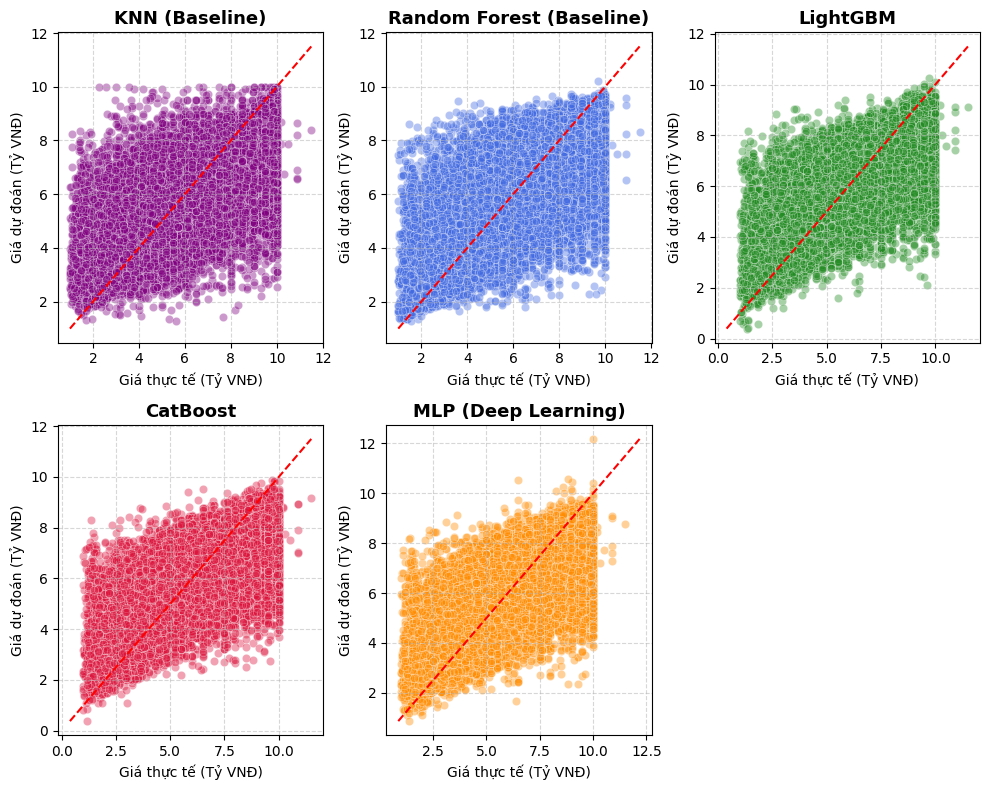

In [ ]:
# Trực quan hóa Scatter Plot cho 5 mô hình
fig, axes = plt.subplots(2, 3, figsize=(10, 8))
axes = axes.ravel()
models_preds = [
    ('KNN (Baseline)', actuals_knn, preds_knn, 'purple'),
    ('Random Forest (Baseline)', actuals_rf, preds_rf, 'royalblue'),
    ('LightGBM', actuals_lgb, preds_lgb, 'forestgreen'),
    ('CatBoost', actuals_cb, preds_cb, 'crimson'),
    ('MLP (Deep Learning)', actuals_mlp, preds_mlp, 'darkorange')
]
for i, (name, actual, pred, color) in enumerate(models_preds):
    sns.scatterplot(x=actual, y=pred, ax=axes[i], alpha=0.4, color=color)
    min_val, max_val = min(min(actual), min(pred)), max(max(actual), max(pred))
    axes[i].plot([min_val, max_val], [min_val, max_val], '--', color='red', lw=1.5)
    axes[i].set_title(name, fontsize=13, fontweight='bold')
    axes[i].set_xlabel('Giá thực tế (Tỷ VNĐ)')
    axes[i].set_ylabel('Giá dự đoán (Tỷ VNĐ)')
    axes[i].grid(True, linestyle='--', alpha=0.5)
axes[5].axis('off')
plt.tight_layout()
plt.show()

## [E4] - FEATURE COMPARISON

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline

print("--- Đang tính toán dữ liệu Trước Feature Engineering để làm mốc đối chứng ---")
# 1. Huấn luyện mô hình LightGBM trên dữ liệu gốc (Raw - loại bỏ ProjectGroup)
cat_cols_raw = [c for c in cat_cols if c != 'ProjectGroup']

lgb_raw_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ]), cat_cols_raw),
])

lgb_raw_pipeline = Pipeline([
    ('prep', lgb_raw_preprocessor),
    ('model', lgb.LGBMRegressor(n_estimators=200, random_state=45, n_jobs=-1, verbose=-1))
])

preds_lgb_raw = []
actuals_lgb_raw = []

for fold, (tr, te) in enumerate(kf.split(X, y)):
    X_raw = X[num_cols + cat_cols_raw]
    lgb_raw_pipeline.fit(X_raw.iloc[tr], y[tr])
    preds_lgb_raw.extend(lgb_raw_pipeline.predict(X_raw.iloc[te]))
    actuals_lgb_raw.extend(y[te])

# 2. Tính toán các chỉ số cho Raw và Feature Engineered
mae_raw = mean_absolute_error(actuals_lgb_raw, preds_lgb_raw)
mse_raw = mean_squared_error(actuals_lgb_raw, preds_lgb_raw)
rmse_raw = np.sqrt(mse_raw)
r2_raw = r2_score(actuals_lgb_raw, preds_lgb_raw)

mae_eng = mean_absolute_error(actuals_lgb, preds_lgb)
mse_eng = mean_squared_error(actuals_lgb, preds_lgb)
rmse_eng = np.sqrt(mse_eng)
r2_eng = r2_score(actuals_lgb, preds_lgb)

# 3. Hiển thị bảng so sánh
print("\n" + " BẢNG SO SÁNH HIỆU QUẢ FEATURE ENGINEERING (LIGHTGBM) ".center(100, "="))

comparison_data = {
    'Chỉ số đánh giá': [
        'MAE (Sai số tuyệt đối)',
        'MSE (Sai số bình phương)',
        'RMSE (Gốc sai số bình phương)',
        'R² Score (Hệ số xác định)'
    ],
    'Trước Feature Engineering': [mae_raw, mse_raw, rmse_raw, r2_raw],
    'Sau Feature Engineering': [mae_eng, mse_eng, rmse_eng, r2_eng],
    'Mức độ cải thiện': [
        f"↓ {mae_raw - mae_eng:.4f}",
        f"↓ {mse_raw - mse_eng:.4f}",
        f"↓ {rmse_raw - rmse_eng:.4f}",
        f"↑ {r2_eng - r2_raw:.4f}"
    ]
}

df_e4 = pd.DataFrame(comparison_data).set_index('Chỉ số đánh giá')
display(df_e4.round(4))

--- Đang tính toán dữ liệu Trước Feature Engineering để làm mốc đối chứng ---


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(



======================= BẢNG SO SÁNH HIỆU QUẢ FEATURE ENGINEERING (LIGHTGBM) =======================


,Trước Feature Engineering,Sau Feature Engineering,Mức độ cải thiện
Chỉ số đánh giá,,,
MAE (Sai số tuyệt đối),1.4090,1.1911,↓ 0.2179
MSE (Sai số bình phương),3.1467,2.3581,↓ 0.7886
RMSE (Gốc sai số bình phương),1.7739,1.5356,↓ 0.2383
R² Score (Hệ số xác định),0.3568,0.5180,↑ 0.1612


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline

# 1. Huấn luyện mô hình LightGBM trên dữ liệu gốc (Raw - loại bỏ ProjectGroup) để lấy mốc đối chứng
cat_cols_raw = [c for c in cat_cols if c != 'ProjectGroup']

lgb_raw_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)),
    ]), cat_cols_raw),
])

lgb_raw_pipeline = Pipeline([
    ('prep', lgb_raw_preprocessor),
    ('model', lgb.LGBMRegressor(n_estimators=200, random_state=45, n_jobs=-1, verbose=-1))
])

preds_lgb_raw = []
actuals_lgb_raw = []

for fold, (tr, te) in enumerate(kf.split(X, y)):
    X_raw = X[num_cols + cat_cols_raw]
    lgb_raw_pipeline.fit(X_raw.iloc[tr], y[tr])
    preds_lgb_raw.extend(lgb_raw_pipeline.predict(X_raw.iloc[te]))
    actuals_lgb_raw.extend(y[te])

# 2. Lưu lại các biến toàn cục để dùng cho các bảng so sánh khác
mae_raw = mean_absolute_error(actuals_lgb_raw, preds_lgb_raw)
mse_raw = mean_squared_error(actuals_lgb_raw, preds_lgb_raw)
rmse_raw = np.sqrt(mse_raw)
r2_raw = r2_score(actuals_lgb_raw, preds_lgb_raw)

mae_eng = mean_absolute_error(actuals_lgb, preds_lgb)
mse_eng = mean_squared_error(actuals_lgb, preds_lgb)
rmse_eng = np.sqrt(mse_eng)
r2_eng = r2_score(actuals_lgb, preds_lgb)

# 3. Tính toán và hiển thị
r2_raw_val = r2_raw
r2_eng_val = r2_eng
r2_diff = r2_eng_val - r2_raw_val

print(f"R² Trước Feature Engineering (Raw): {r2_raw_val:.6f}")
print(f"R² Sau Feature Engineering (Eng): {r2_eng_val:.6f}")
print(f"Mức cải thiện thực tế (R² Eng - R² Raw): +{r2_diff:.6f} ({r2_diff*100:.4f}%)")

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


R² Trước Feature Engineering (Raw): 0.356796
R² Sau Feature Engineering (Eng): 0.517994
Mức cải thiện thực tế (R² Eng - R² Raw): +0.161198 (16.1198%)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


##[E5] - EXPLAINABILITY


=== [E5] GIẢI THÍCH MÔ HÌNH (FEATURE & PERMUTATION IMPORTANCE) ===
2. Trực quan hóa Permutation Importance (Tráo đổi ngẫu nhiên)...


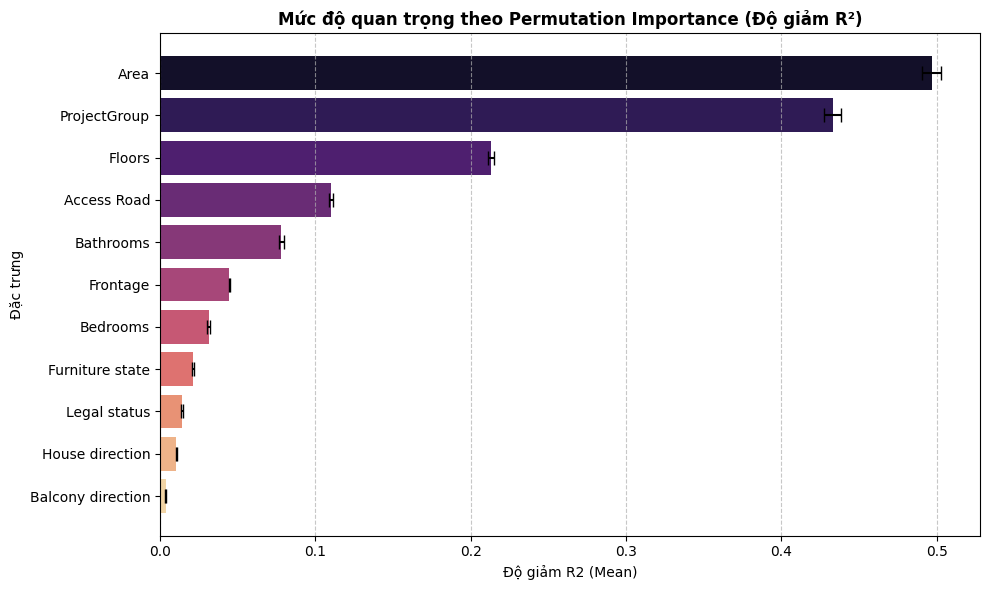

In [ ]:
from sklearn.inspection import permutation_importance

print(" [E5] GIẢI THÍCH MÔ HÌNH (FEATURE & PERMUTATION IMPORTANCE) ")

# --- Chuẩn bị dữ liệu và mô hình ---
X_processed = lgb_preprocessor.fit_transform(X)
feature_names = num_cols + cat_cols
X_processed_df = pd.DataFrame(X_processed, columns=feature_names)

final_lgb_model = lgb.LGBMRegressor(n_estimators=200, random_state=45, n_jobs=-1, verbose=-1)
final_lgb_model.fit(X_processed_df, y)

# ---  PERMUTATION IMPORTANCE ---
print("2. Trực quan hóa Permutation Importance (Tráo đổi ngẫu nhiên)...")
# Tính toán mức độ giảm độ chính xác khi tráo đổi từng đặc trưng
perm_importance = permutation_importance(
    final_lgb_model, X_processed_df, y,
    n_repeats=5, random_state=42, n_jobs=-1
)

# Tạo DataFrame và sắp xếp
perm_df = pd.DataFrame({
    'Đặc trưng': feature_names,
    'Độ giảm R2 (Mean)': perm_importance.importances_mean,
    'Độ lệch chuẩn (Std)': perm_importance.importances_std
}).sort_values(by='Độ giảm R2 (Mean)', ascending=False)

plt.figure(figsize=(10, 6))
# Đã fix cảnh báo palette và bỏ xerr khỏi sns.barplot
sns.barplot(
    x='Độ giảm R2 (Mean)', y='Đặc trưng', data=perm_df,
    hue='Đặc trưng', palette='magma', legend=False
)

# Thêm error bar thủ công bằng Matplotlib để tránh lỗi ValueError
plt.errorbar(
    x=perm_df['Độ giảm R2 (Mean)'],
    y=perm_df['Đặc trưng'],
    xerr=perm_df['Độ lệch chuẩn (Std)'],
    fmt='none', c='black', capsize=5
)

plt.title("Mức độ quan trọng theo Permutation Importance (Độ giảm R²)", fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()